# **ROTATING EQUIPMENT ANOMALY DETECTION**
During the Anomaly Detection phase, the algorithm identifies samples in data set which differ from the normal
operation condition.
We worked on data collected by ENI on rotating machines.


## Setup

In [1]:
!pip install scikit-optimize
!pip install tqdm
!pip install gdown

In [2]:
try:
  from google.colab import drive
  drive.mount('/content/drive/', force_remount=True)
  IN_COLAB = True
except:
  IN_COLAB = False

In [3]:
if not IN_COLAB:
    #download AE_LSTM
    !gdown --id 1SC5OEYKZ2QOPrvaRCYdYKC3apRDdZbZZ
    #download AE
    !gdown --id 1yNZFDnNUaDPCkITQXSmljk0oFqStjxsu
    #download VAE_LSTM
    !gdown --id 1ybV48nvxzq5jAyPQH6JOPux6SgNRb-_5
    #download VAE
    !gdown --id 1wAAXlv6vvjzJgoexHou1QDHYl8r2fKNG
    #download utils.py
    !gdown --id 1-mZDH0qt7qkf6lHeW9HoVYdkf0MOid-a

/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1SC5OEYKZ2QOPrvaRCYdYKC3apRDdZbZZ
From (redirected): https://drive.google.com/uc?id=1SC5OEYKZ2QOPrvaRCYdYKC3apRDdZbZZ&confirm=t&uuid=831e9cd3-e457-486c-88cf-6e70050d1f31
To: /kaggle/working/AE_LSTM.py
100%|██████████████████████████████████████| 5.73k/5.73k [00:00<00:00, 14.9MB/s]
/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1yNZFDnNUaDPCkITQXSmljk0oFqStjxsu
From (redirected): https://drive.google.com/uc?id=1yNZFDnNUaDPCkITQXSmljk0oFqStjxsu&confirm=t&uuid=3e35d699-d343-45d

In [4]:
if not IN_COLAB:
    !mkdir models
    !mv AE.py models
    !mv AE_LSTM.py models
    !mv VAE.py models
    !mv VAE_LSTM.py models

In [5]:
import sys
if IN_COLAB:
    sys.path.append('/content/drive/MyDrive/AI_Industry_Data/AI_Industry_Davide_Luca_Guglielmo_14_10_2024')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import scipy as sp
from utils import *
from models.AE import AE
from models.AE_LSTM import AE_LSTM
from models.VAE import VAE
from models.VAE_LSTM import VAE_LSTM
from sklearn.preprocessing import StandardScaler
from datetime import datetime
import torch.nn.functional as F
import torch
from tqdm import tqdm
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error

from sklearn.metrics import f1_score
from sklearn.model_selection import KFold
from skopt import gp_minimize
from skopt.space import Real
# Create my DatasetClass
from torch.utils.data import DataLoader,Dataset
from torch import nn

In [6]:
figsize=(18, 6)

# Machine: V360KB011B

## Dataset download


In [7]:
if not IN_COLAB:
    #download confirmed anomalies
    !gdown --id 1RHQDSd2YhY7qB4n-xhxEbZqilWr4V3aT
    #download new sensro data
    !gdown --id 1H1YJ9Bpxj-BgM9VlwCPvogaAZNYJMNs5
    #download noc data
    !gdown --id 11uYSF7DnguUWJrWXTxPD7mhxEZa0HiId
    #download old train card
    !gdown --id 12xCHG6aK90i1JWB4gytj-01LfwJDYhxA

/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1RHQDSd2YhY7qB4n-xhxEbZqilWr4V3aT
To: /kaggle/working/11B_confirmed_anomalies.xlsx
100%|██████████████████████████████████████| 13.4k/13.4k [00:00<00:00, 27.9MB/s]
/usr/local/lib/python3.10/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1H1YJ9Bpxj-BgM9VlwCPvogaAZNYJMNs5
From (redirected): https://drive.google.com/uc?id=1H1YJ9Bpxj-BgM9VlwCPvogaAZNYJMNs5&confirm=t&uuid=5e16108f-08e5-45cc-a079-f390eaaa538f
To: /kaggle/working/11B_sensorsdata_new.csv
100%|████████████████████████████████████████| 536M/536M [00:05<0

In [8]:
name_machine = 'V360KB011B'
dataset_folder = ""

if IN_COLAB:
   dataset_folder = f"/content/drive/MyDrive/AI_Industry_Data/new_data/V360KB011B/"  # CHANGE HERE THE DATA FOLDER
    
noc_data = pd.read_csv(dataset_folder + f"noc_data_{name_machine}_111.csv",sep=";")
sensor_data = pd.read_csv(dataset_folder + f"11B_sensorsdata_new.csv",sep=",")
train_card = pd.read_csv(dataset_folder + f"train_card_{name_machine}_111.csv",sep=";")
confirmed_anomalies = pd.read_excel(dataset_folder + f"11B_confirmed_anomalies.xlsx")
confirmed_anomalies.rename(columns={'anomaly_start': 'range_start', 'anomaly_end': 'range_end'}, inplace=True)
confirmed_anomalies["range_start"] = confirmed_anomalies.apply(lambda x : str(x["range_start"]),axis=1)
confirmed_anomalies["range_end"] = confirmed_anomalies.apply(lambda x : str(x["range_end"]),axis=1)

# Cols to consider
target_cols = sensor_data.columns[1:]

`noc_data` contains the time intervals in which we assumes there are not anomalies (NOC == _Normal Operating Conditions_).

In [9]:
noc_data.head()

,id_training,range_start,range_end,id_train
0,111,2023-01-01 00:00:00,2024-01-31 00:00:00,V360KB011B


`confirmed_anomalies` contains the time intervals in which we know there are anomalies.

In [10]:
confirmed_anomalies.head()

,range_start,range_end
0,2024-07-14 00:00:00,2024-07-17 00:00:00
1,2024-09-30 00:00:00,2024-10-15 00:00:00


Each row in `train_card` contains the information about each sensor found in `sensor_data`.

In [11]:
train_card.head()

/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.10/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,id_train,asset_id,train_type,equipment_type,id_sensor,is_operating,will_be_available,pi_acquisition_date,pi_description,sensor_description,unit,tag_id,priority,onoff_parameter,boot_threshold,for_ml,efficiency_index
0,V360KB011B,COVA,HP Compressor,Compressor,COVA.ABB.V360TT231.pv,1.0,2,NaN,USC V360VN011B,Suction Scrubber Outlet Temperature,degC,1,1.0,0,0,0,0
1,V360KB011B,COVA,HP Compressor,Compressor,COVA.ABB.V360LIC233.pv,1.0,2,NaN,V360VN011B,Suction Scrubber Level,%,2,1.0,0,0,0,0
2,V360KB011B,COVA,HP Compressor,Compressor,COVA.ABB.V360PT232.pv,1.0,2,NaN,mandata gas AP KB011B,Cooler Inlet Pressure,barG,3,1.0,0,0,1,0
3,V360KB011B,COVA,HP Compressor,Compressor,COVA.ABB.V360-PI731B.pv,1.0,2,NaN,PRESS. OLIO LUBRIF.,Lube Oil Pressure,bar,4,1.0,0,0,1,0
4,V360KB011B,COVA,HP Compressor,Motor,COVA.ABB.V360-TI762B.pv,1.0,2,NaN,TEMP.AVVOL.MOT.PRIN.,Stator Windings Temperature Phase A,degC,5,1.0,0,0,1,0


`sensor_data` contains the real data (time series), i.e. the values for each sesnor every 30 seconds.

In [12]:
sensor_data["sensor_ts"] = sensor_data.apply(lambda x : x["sensor_ts"].replace("T", " ")[:-6],axis=1)

In [13]:
sensor_data.head()


,sensor_ts,COVA.ABB.V360-PI701B.pv,COVA.ABB.V360-PI704B.pv,COVA.ABB.V360-PI731B.pv,COVA.ABB.V360-TI702B.pv,COVA.ABB.V360-TI703B.pv,COVA.ABB.V360-TI704B.pv,COVA.ABB.V360-TI706B.pv,COVA.ABB.V360-TI731B.pv,COVA.ABB.V360-TI732B.pv,...,COVA.ABB.V360PIC237.out,COVA.ABB.V360PIC237.pv,COVA.ABB.V360PT232.pv,COVA.ABB.V360PV237.pv,COVA.ABB.V360TIC233.pv,COVA.ABB.V360TIC233.pvl,COVA.ABB.V360TT231.pv,COVA.ABB.V360TT232.pv,COVA.ABB.V470-A155-A.pv,Eni.VDA.KPI.V360-KB-011B.CompEfficiency
0,2023-01-01 00:00:00,23.25091,61.50574,3.4,58.10727,60.07882,103.8738,109.2365,57.81053,53.22153,...,0.0,23.74531,62.21875,18.79463,13.11009,50.375,34.575,106.5,4.7,0.870687
1,2023-01-01 00:00:30,23.20109,61.52445,3.4,58.14772,60.12020,103.9280,109.3115,57.80949,53.21890,...,0.0,23.74531,62.21875,18.17180,12.99755,50.375,34.575,106.5,4.7,0.870778
2,2023-01-01 00:01:00,23.15128,61.54317,3.4,58.18818,60.16158,103.9821,109.3865,57.80846,53.21627,...,0.0,23.74531,62.21875,17.54897,12.88502,50.375,34.575,106.5,4.7,0.870869
3,2023-01-01 00:01:30,23.10147,61.56188,3.4,58.22863,60.20296,104.0363,109.5230,57.80743,53.21363,...,0.0,23.74531,62.21875,16.92614,12.77249,50.375,34.575,106.5,4.7,0.870960
4,2023-01-01 00:02:00,23.05165,61.58059,3.4,58.26909,60.24434,104.0905,109.6730,57.80639,53.21100,...,0.0,23.74531,62.21875,16.30331,12.65995,50.375,34.575,106.5,4.7,0.871051


### Adding `NOC` and `anomalies` columns


In [14]:
# adding NOC label based on NOC intervals
sensor_data_training = consider_range(noc_data, sensor_data)
sensor_data = add_labels(sensor_data, sensor_data_training, labels = 'NOC')

In [15]:
# adding anomaly label based on anomaly intervals
sensor_data_training = consider_range(confirmed_anomalies, sensor_data)
sensor_data = add_labels(sensor_data, sensor_data_training, labels = 'anomaly')

In [16]:
# eliminate useless colums from train card
train_card = cut_col(train_card)

In [17]:
sensor_data[sensor_data['anomaly']==1].head(-1)

,sensor_ts,COVA.ABB.V360-PI701B.pv,COVA.ABB.V360-PI704B.pv,COVA.ABB.V360-PI731B.pv,COVA.ABB.V360-TI702B.pv,COVA.ABB.V360-TI703B.pv,COVA.ABB.V360-TI704B.pv,COVA.ABB.V360-TI706B.pv,COVA.ABB.V360-TI731B.pv,COVA.ABB.V360-TI732B.pv,...,COVA.ABB.V360PT232.pv,COVA.ABB.V360PV237.pv,COVA.ABB.V360TIC233.pv,COVA.ABB.V360TIC233.pvl,COVA.ABB.V360TT231.pv,COVA.ABB.V360TT232.pv,COVA.ABB.V470-A155-A.pv,Eni.VDA.KPI.V360-KB-011B.CompEfficiency,NOC,anomaly
1612560,2024-07-14 00:00:00,23.02479,55.86536,3.8,61.60228,58.80059,103.4576,115.0090,60.53595,55.92089,...,56.06250,26.89211,24.41832,50.4375,38.79375,109.2500,22.92406,0.578519,0,1
1612561,2024-07-14 00:00:30,23.04979,55.85667,3.8,61.50447,58.80132,103.3719,114.9590,60.53521,55.91821,...,56.06250,26.71780,24.28633,50.4375,38.79375,109.2500,22.90000,0.578608,0,1
1612562,2024-07-14 00:01:00,23.07479,55.84798,3.8,61.38763,58.80203,103.2862,114.9089,60.53446,55.91552,...,56.06250,26.54349,24.15434,50.4375,38.79375,109.2500,22.90000,0.578697,0,1
1612563,2024-07-14 00:01:30,23.09980,55.83929,3.8,61.27079,58.80275,103.2004,114.8589,60.53371,55.91283,...,56.06250,26.36918,24.02236,50.4375,38.79375,109.2500,22.90000,0.578786,0,1
1612564,2024-07-14 00:02:00,23.07520,55.83059,3.8,61.15394,58.80347,103.1147,114.8089,60.53297,55.91014,...,56.06250,26.19487,23.89037,50.4375,38.79375,109.2500,22.90000,0.578874,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1880395,2024-10-14 23:57:30,23.80000,62.57172,3.9,60.56630,54.70793,104.6034,109.0162,57.91859,54.24650,...,62.34375,19.04759,30.36799,50.4375,35.60625,107.1875,12.60000,0.824005,0,1
1880396,2024-10-14 23:58:00,23.80000,62.56933,3.9,60.55241,54.70543,104.6249,109.0876,57.91779,54.24510,...,62.34375,19.30958,30.23633,50.4375,35.60625,107.1875,12.60000,0.824222,0,1
1880397,2024-10-14 23:58:30,23.80000,62.56694,3.9,60.53852,54.70293,104.6463,109.1000,57.91698,54.24370,...,62.34375,19.57158,30.10468,50.4375,35.60625,107.1875,12.60000,0.824439,0,1
1880398,2024-10-14 23:59:00,23.75036,62.56455,3.9,60.52463,54.70043,104.6677,109.1000,57.91618,54.24230,...,62.34375,19.83357,29.97302,50.4375,35.60625,107.1875,12.60000,0.824656,0,1


## Pre-Processing
We have replicated the ENI preprocessing which involves the following steps:

1.   Drop offline time ranges-on/off parameter given
2.   Drop nan
3.   Scale the data
4.   Exclude flat sensors
5.   Smooth with rolling average

### 1.   Drop offline time ranges-on/off parameter given

In [18]:
# Drop offline time ranges – On/Off parameter a
print("Dataset shape before dropping: ", len(sensor_data))
len_df = len(sensor_data)

data_to_remove = train_card[train_card['onoff_parameter']== 1 ][['boot_threshold','id_sensor']].groupby('id_sensor').first().reset_index()
for i in range(len(data_to_remove)):
  dtr = data_to_remove.iloc[i]
  sensor_data = sensor_data.drop(np.where(sensor_data[dtr['id_sensor']] <= dtr['boot_threshold'])[0])

print("Dataset shape after dropping: ", len(sensor_data))

Dataset shape before dropping:  1989841
Dataset shape after dropping:  1170479


#### Distances Calculation

In [19]:
sample_n = 300
distance = sp.stats.wasserstein_distance_nd(sensor_data[sensor_data["anomaly"] == 0][target_cols].sample(sample_n,random_state=42),sensor_data[sensor_data["anomaly"] == 1][target_cols].sample(sample_n,random_state=42))
print("Wasserstein distance : ")
print(f" new dataset {distance}")

Wasserstein distance : 
 new dataset 5947.490232968861


In [21]:
distance = sp.spatial.distance.jensenshannon(sensor_data[sensor_data["anomaly"] == 0][target_cols].sample(sample_n,random_state=42),sensor_data[sensor_data["anomaly"] == 1][target_cols].sample(sample_n,random_state=42))

print("JensenShannon distances : ")

new = pd.Series(distance).replace([np.inf, -np.inf], np.nan).dropna()
print(f" new dataset {new.mean()}")

JensenShannon distances : 
 new dataset 0.07662672000531558


### 2.   Drop NaN


In [16]:
print("Dataset shape before dropping:", sensor_data.shape)

# Drop columns and rows where all values are NaN
sensor_data.dropna(axis=0, how='all', subset=target_cols, inplace=True)
sensor_data.dropna(axis=1, how='all', inplace=True)

# Drop rows with NaN values
sensor_data = sensor_data.dropna()

# Reset the index
sensor_data.reset_index(drop=True, inplace=True)

print("Dataset shape after dropping:", sensor_data.shape)

Dataset shape before dropping: (1170479, 34)
Dataset shape after dropping: (1169562, 34)


### 3.   Scale the data


In [17]:
##Scaler fitted on the training data and applied to all the dataset (the training must be independent from the test)

# Initialize the StandardScaler
scaler = StandardScaler()

# Train Test = NOC data
training_data = sensor_data[sensor_data['NOC'] == 1]

train_data = training_data[:].iloc[:,1:-2]
anomaly_column = training_data.iloc[:,-1]
train_ts = training_data.iloc[:,0]

# Fit the Scaler with train_data
scaler.fit(train_data)

# Transform data usign the Scaler
scaled_train_data = scaler.transform(train_data)

# Convert the scaled data back to a DataFrame
scaled_train_df = pd.DataFrame(scaled_train_data, index=train_data.index, columns=train_data.columns)
scaled_train_df.insert(0, 'sensor_ts', train_ts)
scaled_train_df['anomaly'] = anomaly_column.values

scaled_train_df = scaled_train_df.reset_index(drop = True)

In [18]:
scaled_train_df.head(-5)

,sensor_ts,COVA.ABB.V360-PI701B.pv,COVA.ABB.V360-PI704B.pv,COVA.ABB.V360-PI731B.pv,COVA.ABB.V360-TI702B.pv,COVA.ABB.V360-TI703B.pv,COVA.ABB.V360-TI704B.pv,COVA.ABB.V360-TI706B.pv,COVA.ABB.V360-TI731B.pv,COVA.ABB.V360-TI732B.pv,...,COVA.ABB.V360PIC237.pv,COVA.ABB.V360PT232.pv,COVA.ABB.V360PV237.pv,COVA.ABB.V360TIC233.pv,COVA.ABB.V360TIC233.pvl,COVA.ABB.V360TT231.pv,COVA.ABB.V360TT232.pv,COVA.ABB.V470-A155-A.pv,Eni.VDA.KPI.V360-KB-011B.CompEfficiency,anomaly
0,2023-01-01 00:00:00,1.438110,0.687795,-0.719965,-0.399303,0.495970,0.587486,0.645327,-0.546672,-0.624157,...,1.593382,0.831620,-0.243186,-1.773128,0.591483,0.400433,0.348219,-1.082761,0.484169,0
1,2023-01-01 00:00:30,1.232787,0.693482,-0.719965,-0.383779,0.511140,0.599095,0.660592,-0.547727,-0.625935,...,1.593382,0.831620,-0.287375,-1.784163,0.591483,0.400433,0.348219,-1.082761,0.484937,0
2,2023-01-01 00:01:00,1.027504,0.699173,-0.719965,-0.368252,0.526309,0.610683,0.675856,-0.548772,-0.627712,...,1.593382,0.831620,-0.331564,-1.795197,0.591483,0.400433,0.348219,-1.082761,0.485705,0
3,2023-01-01 00:01:30,0.822222,0.704860,-0.719965,-0.352728,0.541479,0.622292,0.703636,-0.549817,-0.629496,...,1.593382,0.831620,-0.375753,-1.806232,0.591483,0.400433,0.348219,-1.082761,0.486473,0
4,2023-01-01 00:02:00,0.616899,0.710547,-0.719965,-0.337200,0.556649,0.633902,0.734164,-0.550872,-0.631273,...,1.593382,0.831620,-0.419943,-1.817267,0.591483,0.400433,0.348219,-1.082761,0.487240,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
747506,2024-01-30 10:00:30,1.228995,0.959587,1.060158,1.619312,1.034831,0.304234,0.575336,0.047100,-1.117343,...,0.964724,0.860024,-1.576648,1.298551,-1.144217,-1.796038,0.587143,-1.036434,-4.347964,0
747507,2024-01-30 10:01:00,1.023672,0.944517,1.060158,1.669172,1.037445,0.343496,0.622818,0.047688,-1.124087,...,0.964724,0.860024,-1.463680,1.241089,-0.307479,-1.796038,0.587143,-1.042839,-4.352793,0
747508,2024-01-30 10:01:30,0.817689,0.929319,1.060158,1.719032,1.040063,0.382758,0.670299,0.048276,-1.130832,...,0.625217,0.860024,-1.349946,1.183106,0.534931,-1.796038,0.587143,-1.049235,-4.357621,0
747509,2024-01-30 10:02:00,0.611664,0.914121,1.060158,1.768888,1.042680,0.422020,0.717781,0.048875,-1.137583,...,-0.173482,0.860024,-1.338540,1.172742,0.538886,-1.796038,0.587143,-1.055627,-4.362450,0


### 4.   Exclude flat sensors


In [19]:
# Find columns with constant values
constant_cols = scaled_train_df.columns[scaled_train_df.nunique() == 1]

print("Sensors with constant values :", constant_cols.values)

# Drop the constant columns from the DataFrame
scaled_train_df = scaled_train_df.drop(columns=constant_cols)

print("Dataset shape after drop : ", scaled_train_df.shape)

Sensors with constant values : ['anomaly']
Dataset shape after drop :  (747516, 32)


### 5.   Smooth with rolling average

In [20]:
import gc
gc.collect()

128

In [21]:
# Smoothing
sensor_ts = scaled_train_df['sensor_ts']

scaled_train_df['sensor_ts'] = pd.to_datetime(scaled_train_df['sensor_ts'])

# Set the 'timestamp' column as the index
scaled_train_df.set_index('sensor_ts', inplace=True)

# Calculate the rolling mean using a 5-minute window, handling time gaps
scaled_train_df[target_cols] = scaled_train_df[target_cols].rolling('3000min').mean()

# reset the index
scaled_train_df.reset_index(inplace=True)

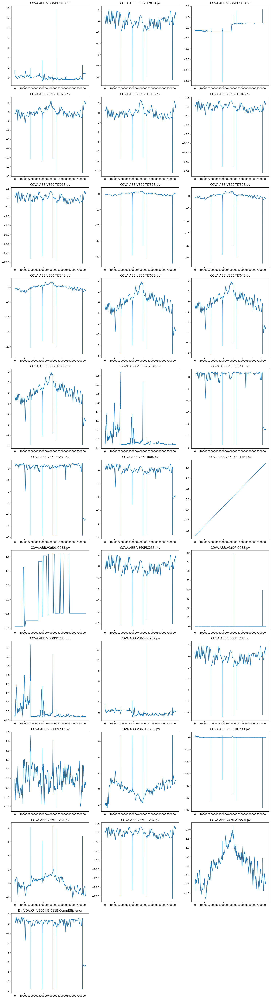

In [22]:
plot_columns_in_grid(scaled_train_df, target_cols)

## Train/Test split


In [52]:
# Test data = Non-NOC data
testing_data = sensor_data[sensor_data['NOC'] == 0]

test_data = testing_data[:].iloc[:,1:-2]
test_ts = testing_data.iloc[:,0]
anomaly_column = testing_data.iloc[:,-1]

# Transform data using the Scaler fittet on the training set
scaled_test_data = scaler.transform(test_data)

# Convert the scaled data back to a DataFrame
scaled_test_df = pd.DataFrame(scaled_test_data, index=test_data.index, columns=test_data.columns)
scaled_test_df.insert(0, 'sensor_ts', test_ts)
scaled_test_df['anomaly'] = anomaly_column.values

scaled_test_df = scaled_test_df.reset_index(drop = True)

# Traing and Testing datasets
train_df = scaled_train_df
test_df = scaled_test_df[:200000]

# Defining inputs of our model
inputs = target_cols

print("Train shape: ", train_df.shape)
print("Test shape: ", test_df.shape)

Train shape:  (747516, 32)
Test shape:  (200000, 33)


In [24]:
#tsdata = redistribute_nnoc(tsdata,n = 5)

# ***GMM*** - *Gaussian Mixture Model* (Baseline)

As a baseline we are using a **GMM**, namely a a probabilistic model that represents data as a mixture of multiple Gaussian distributions, each defined by its mean and covariance. It is often used for clustering, density estimation, or modeling complex distributions

In [53]:
import gc
gc.collect()

3067

In [68]:
new_input = inputs[:-1]
new_input


Index(['COVA.ABB.V360-PI701B.pv', 'COVA.ABB.V360-PI704B.pv',
       'COVA.ABB.V360-PI731B.pv', 'COVA.ABB.V360-TI702B.pv',
       'COVA.ABB.V360-TI703B.pv', 'COVA.ABB.V360-TI704B.pv',
       'COVA.ABB.V360-TI706B.pv', 'COVA.ABB.V360-TI731B.pv',
       'COVA.ABB.V360-TI732B.pv', 'COVA.ABB.V360-TI734B.pv',
       'COVA.ABB.V360-TI762B.pv', 'COVA.ABB.V360-TI764B.pv',
       'COVA.ABB.V360-TI766B.pv', 'COVA.ABB.V360-ZI237P.pv',
       'COVA.ABB.V360FT231.pv', 'COVA.ABB.V360FY231.pv',
       'COVA.ABB.V360II004.pv', 'COVA.ABB.V360KB011BT.pv',
       'COVA.ABB.V360LIC233.pv', 'COVA.ABB.V360PIC233.mv',
       'COVA.ABB.V360PIC233.pv', 'COVA.ABB.V360PIC237.out',
       'COVA.ABB.V360PIC237.pv', 'COVA.ABB.V360PT232.pv',
       'COVA.ABB.V360PV237.pv', 'COVA.ABB.V360TIC233.pv',
       'COVA.ABB.V360TIC233.pvl', 'COVA.ABB.V360TT231.pv',
       'COVA.ABB.V360TT232.pv', 'COVA.ABB.V470-A155-A.pv'],
      dtype='object')

In [78]:
# Define the parameter grid
param_grid = {'n_components': [2, 4, 8, 16]}

gmm = GaussianMixture(16)

opt = GridSearchCV(
    estimator=gmm,
    param_grid=param_grid,
    cv=3,
    verbose=3,    # Set to 3 for detailed logs
    n_jobs=-1     # Use all available CPU cores
)

gmm.fit(train_df[new_input])


# Print the best parameters
#print(f'Best parameters: {opt.best_params_}')

GaussianMixture(n_components=16)

In [79]:
# This computes the log probability density of the data points in the test set
ldens = gmm.score_samples(test_df[new_input])
signal = pd.Series(index=test_df.index, data=-ldens)

##Find the best threshold

In [81]:
gmm_best_threshold, gmm_best_score = threshold_optimization(signal, test_df['anomaly'], method = 'bayesian')

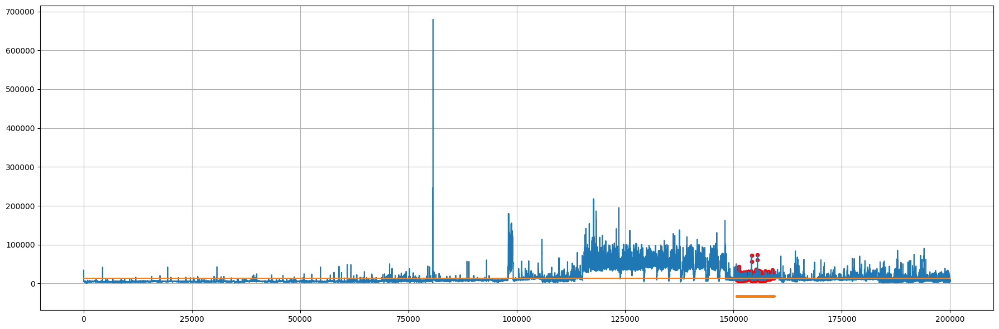

In [82]:
plot_signal(signal, test_df['anomaly'], figsize=figsize, threshold = gmm_best_threshold)

#Deep Learning Models
After the GMM baseline we trained 4 different models (AE, AE_LSTM, VAE and VAE_LSTM)

# Settings

In [ ]:
batch_size = 32

if torch.cuda.is_available():
  device = torch.device("cuda:0")
else:
  device = torch.device("cpu")

# Define the dataset NOT SLIDED
trdata_dataset = MyDataset(train_df[target_cols], device =device)
tsdata_dataset = MyDataset(test_df[target_cols], device =device)

# Define DataLoader
trdata_loader = DataLoader(trdata_dataset,batch_size=batch_size,shuffle=False)
tsdata_loader = DataLoader(tsdata_dataset,batch_size=batch_size,shuffle=False)

In [ ]:
input_size = len(target_cols)
hidden_size = 128
latent_size = 64
epochs = 10

# Train & Evaluation

In [ ]:
true_labels = test_df['anomaly']

## AE

 A simple **Autoencoder** with two main components:

- Encoder: Two linear layers compress the input to a latent space.
- Decoder: Two linear layers reconstruct the input from the latent space.
The model uses **Mean Squared Error** (MSE) for reconstruction loss, and training is handled with the Adam optimizer. It includes early stopping for efficiency, and there are methods for evaluation, prediction, and plotting loss history to monitor performance.

Output: A reconstructed version of the input and a reconstruction error signal with the same size of input.

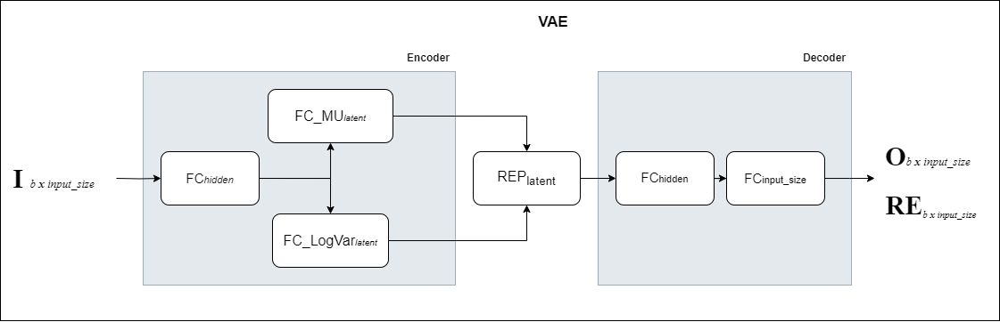

In [ ]:
# Define VAE model
ae = AE(input_size, hidden_size, latent_size, device = device).to(device)
_,_ = ae.fit(trdata_loader, num_epochs=epochs, plot_history = False)

Epoch 1/10, Loss: 0.4158


Epoch 2/10, Loss: 0.5393


Epoch 3/10, Loss: 0.3666


Epoch 4/10, Loss: 0.4275


Epoch 5/10, Loss: 0.3082


Epoch 6/10, Loss: 0.2595


Epoch 7/10, Loss: 0.3348


Epoch 8/10, Loss: 0.2974


Epoch 9/10, Loss: 0.4447
Early stopping!


In [ ]:
ae_preds_test,ae_signal_test = ae.predict(tsdata_loader)

In [ ]:
# Convert into dataframe
ae_preds_test = pd.DataFrame(ae_preds_test.cpu().detach().numpy(), columns = target_cols)
ae_signal_test_col = pd.Series(ae_signal_test.mean(dim = 0).cpu().detach().numpy(), index = target_cols)
ae_signal_test_row = pd.Series(ae_signal_test.mean(dim = 1).cpu().detach().numpy())
ae_signal_test = pd.DataFrame(ae_signal_test.cpu().detach().numpy(), columns = target_cols)

### Signal comparison (ground truth vs prediction)




In [ ]:
plot_predicted_on_real_signal(test_df[target_cols], ae_preds_test)

### Plot the signal reconstruction error by feature

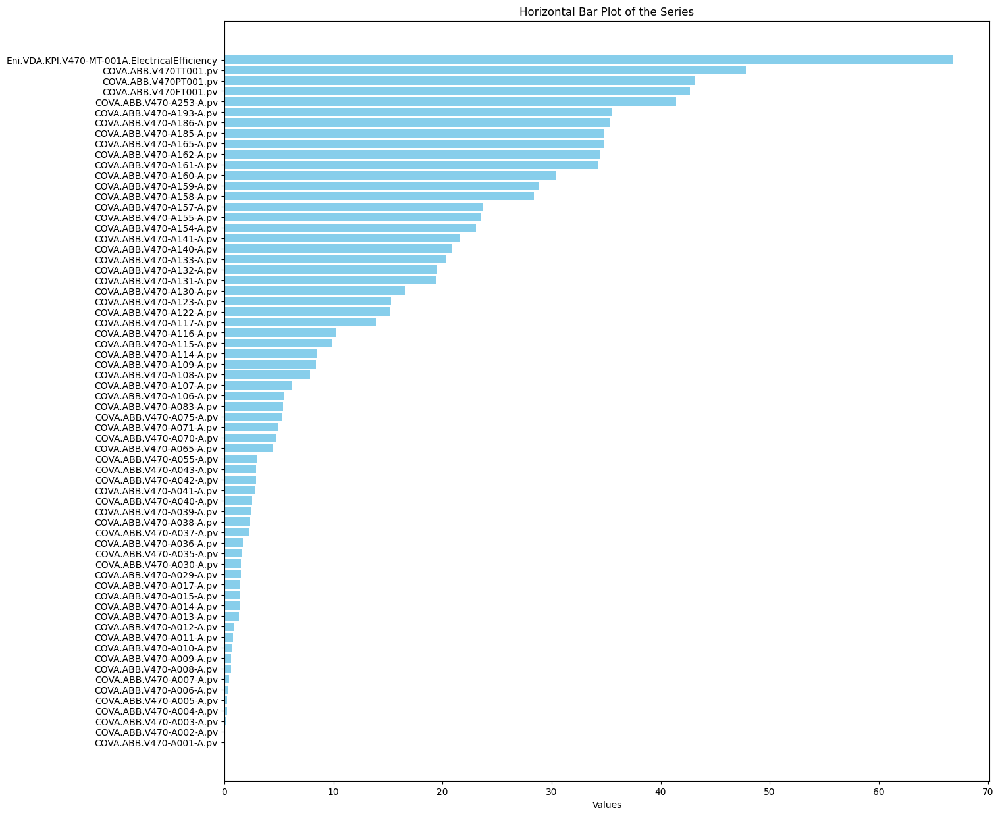

In [ ]:
plt.figure(figsize=(15, 15))
plt.barh(target_cols, ae_signal_test_col.sort_values(ascending = True), color='skyblue')
plt.xlabel('Values')
plt.title('Horizontal Bar Plot of the Series')
plt.show()

### Find the best threshold
Threshold optimization using different methos

In [ ]:
# Possible methods = ['bayesian' , 'simple' , 'cross_validation']
ae_best_threshold, ae_best_score = threshold_optimization(ae_signal_test_row, test_df['anomaly'], method = 'bayesian')

### Plot the reconstruction error with anomaly threshold

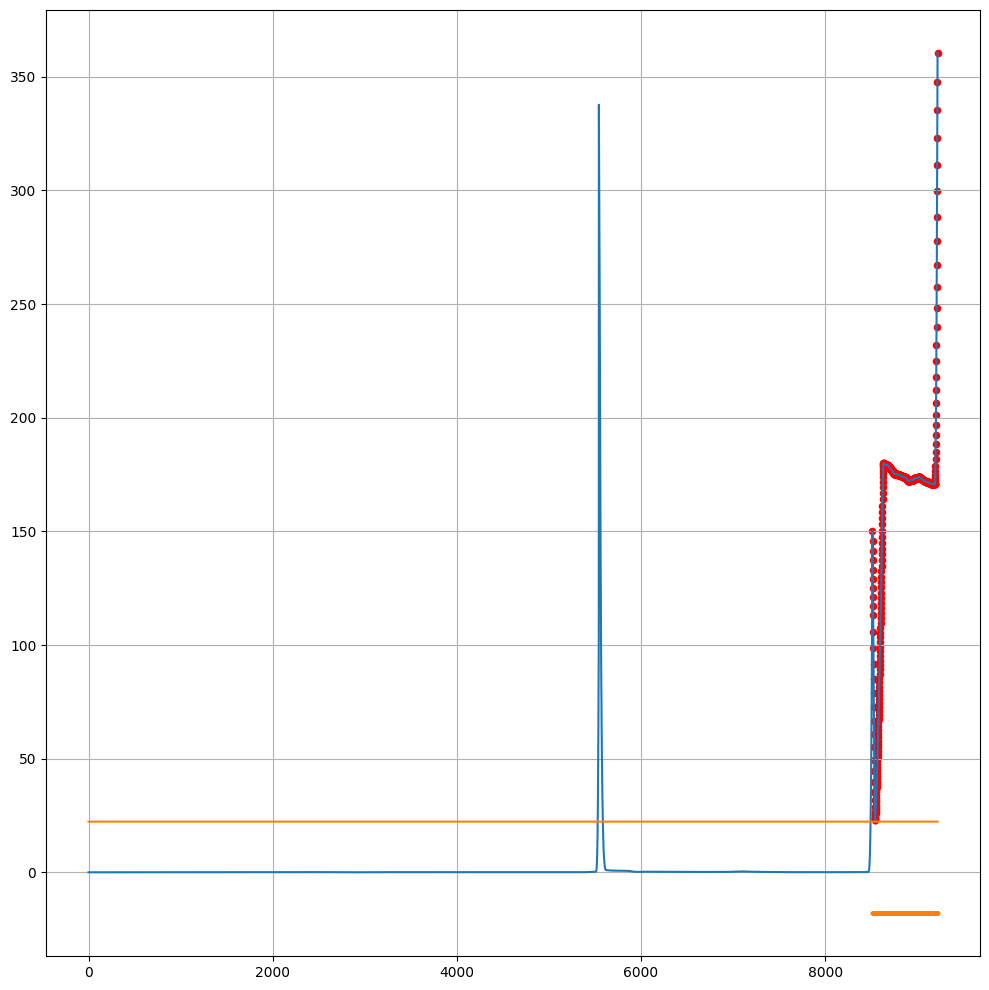

In [ ]:
plot_signal(ae_signal_test_row, labels =true_labels ,threshold = ae_best_threshold)

## AE_LSTM

An LSTM-based Autoencoder (AE-LSTM) implementation:

- Encoder: Uses an LSTM layer to encode the input sequence into a hidden state, which is then passed through a fully connected layer to map it to the latent space.
- Decoder: Uses another LSTM to decode the latent vector by repeating it for each timestep in the sequence, then a dense layer reconstructs the original input sequence.
The loss function is the Mean Squared Error (MSE) between the input and reconstructed sequence.

Training: the Adam optimizer with early stopping. \
Output: A reconstructed version of the input and a reconstruction error signal with the same size of input.

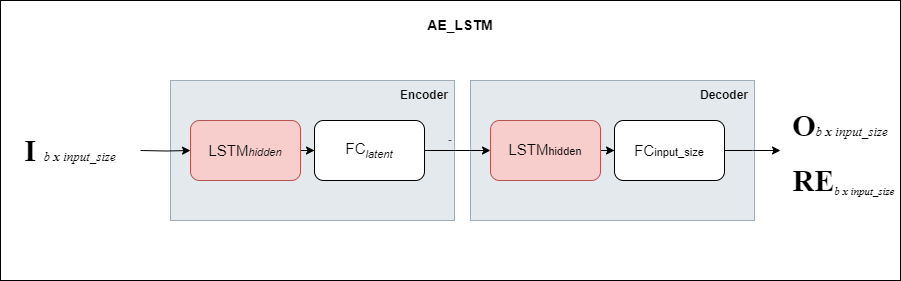

### Train

In [ ]:
# Define VAE model
ae_lstm = AE_LSTM(input_size, hidden_size, latent_size, device = device).to(device)
#best_epoch,_ = optimize_epochs(copy.deepcopy(ae), trdata_loader, valdata_loader, plot_history = True)
#print("best epoch : " , best_epoch)
_,_ = ae_lstm.fit(trdata_loader, num_epochs=epochs, plot_history = False)

Epoch 1/10, Loss: 0.6124


Epoch 2/10, Loss: 0.4052


Epoch 3/10, Loss: 0.3775


Epoch 4/10, Loss: 0.3327


Epoch 5/10, Loss: 0.2878


Epoch 6/10, Loss: 0.3701


Epoch 7/10, Loss: 0.2777


Epoch 8/10, Loss: 0.2648


Epoch 9/10, Loss: 0.2329


Epoch 10/10, Loss: 0.2191


In [ ]:
ae_lstm_preds_test,ae_lstm_signal_test = ae_lstm.predict(tsdata_loader)

In [ ]:
ae_lstm_preds_test = pd.DataFrame(ae_lstm_preds_test.cpu().detach().numpy(), columns = target_cols)
ae_lstm_signal_test_col = pd.Series(ae_lstm_signal_test.mean(dim = 0).cpu().detach().numpy(), index = target_cols)
ae_lstm_signal_test_row = pd.Series(ae_lstm_signal_test.mean(dim = 1).cpu().detach().numpy())
ae_lstm_signal_test = pd.DataFrame(ae_lstm_signal_test.cpu().detach().numpy(), columns = target_cols)

### Signal comparison (ground truth vs prediction)





In [ ]:
plot_predicted_on_real_signal(test_df[target_cols], ae_lstm_preds_test)

### Plot the signal reconstruction error by feature

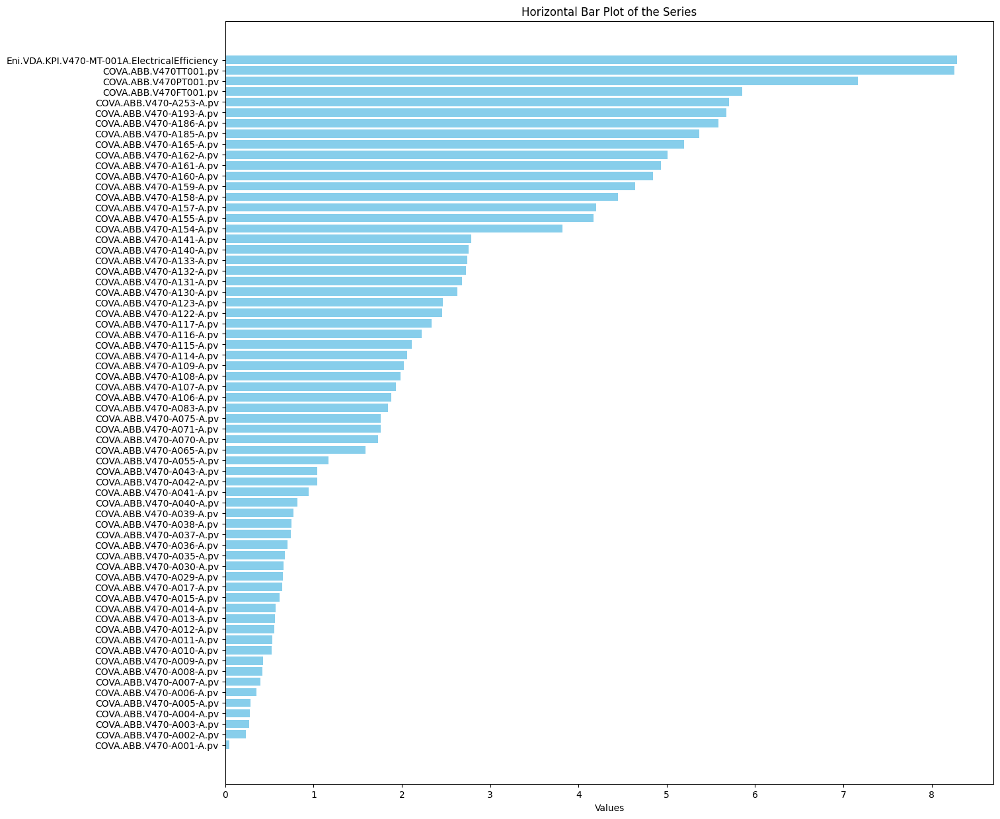

In [ ]:
plt.figure(figsize=(15, 15))
plt.barh(target_cols, ae_lstm_signal_test_col.sort_values(ascending = True), color='skyblue')
plt.xlabel('Values')
plt.title('Horizontal Bar Plot of the Series')
plt.show()

### Find the best threshold
Threshold optimization using different methos

In [ ]:
# Possible methods = ['bayesian' , 'simple' , 'cross_validation']
ae_lstm_best_threshold, ae_lstm_best_score = threshold_optimization(ae_lstm_signal_test_row, test_df['anomaly'], method = 'bayesian')

### Plot the reconstruction error with anomaly threshold

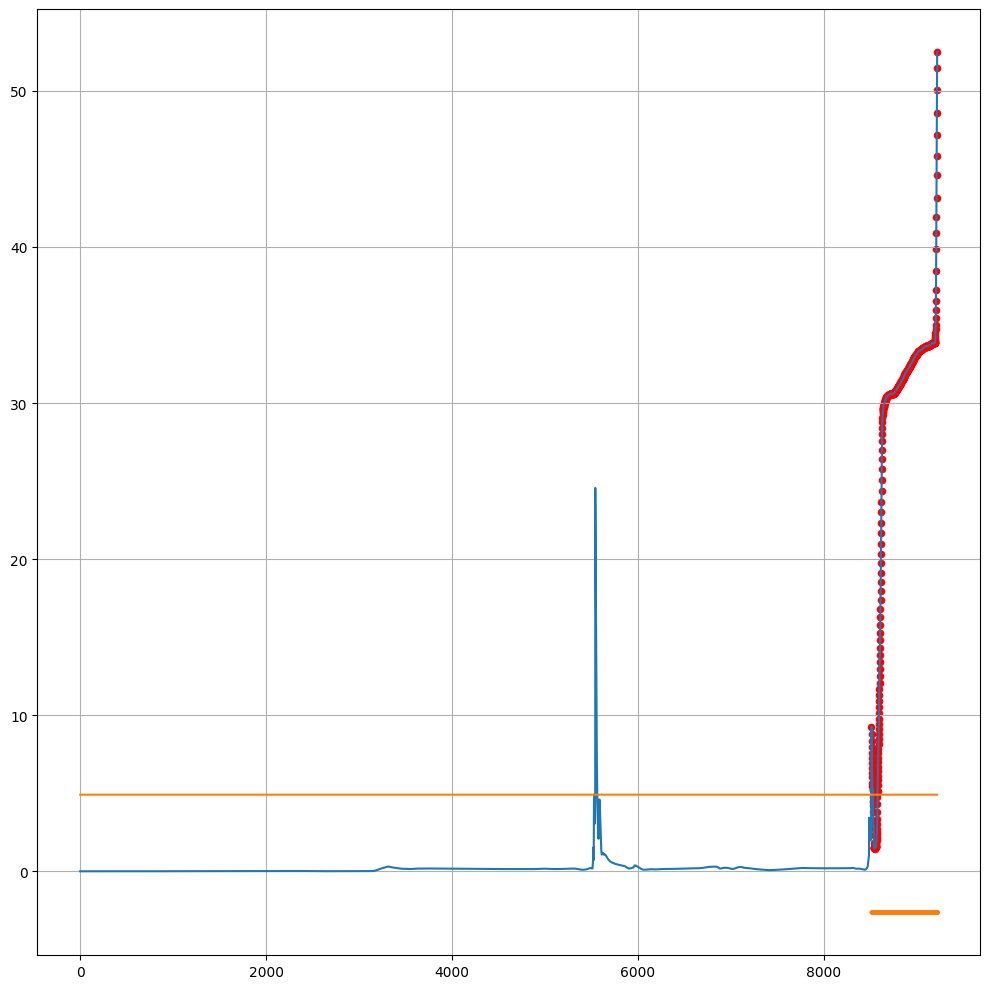

In [ ]:
plot_signal(ae_lstm_signal_test_row, labels =true_labels ,threshold = ae_lstm_best_threshold)

In [ ]:
print(np.mean(ae_signal_test))
print(np.mean(ae_lstm_signal_test))

13.50371
2.3692005


## VAE

A Variational Autoencoder (VAE) implementation:

- **Encoder**: The encoder consists of fully connected layers that transform the input into two outputs—mean (mu) and log-variance (logvar)—which are used to generate latent space representations using the reparameterization trick.

- **Decoder**: The decoder reconstructs the original input from the latent space vector using two fully connected layers. The output is normalized using a sigmoid function to ensure values between 0 and 1.

- **Reparameterization**: In the latent space, the model samples from the distribution defined by mu and logvar using the formula: z = mu + std * eps, where eps is a random normal variable.

- **Loss Function**: Combines two components
*   Reconstruction Loss (MSE) between the original input and reconstructed output.
*   KL Divergence between the learned latent distribution and a standard Gaussian distribution to regularize the latent space.

- **Training**: The model is trained using the Adam optimizer with early stopping and tracks loss through epochs. The fit method handles training and optional validation, while also allowing the option to visualize training and validation loss over time.

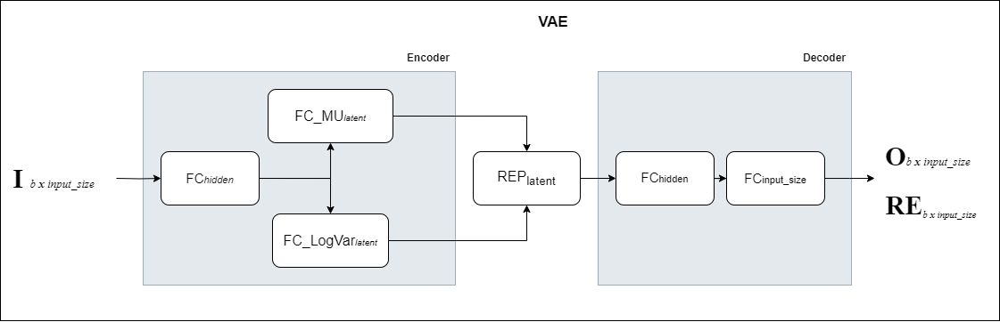

In [ ]:
vae = VAE(input_size, hidden_size, latent_size, device = device).to(device)
_,_ = vae.fit(trdata_loader, num_epochs=epochs, plot_history = False)

Epoch 1/10, Loss: 3.4028
Epoch 2/10, Loss: 1.5087
Epoch 3/10, Loss: 0.0991
Epoch 4/10, Loss: 0.0551
Epoch 5/10, Loss: 0.0441
Epoch 6/10, Loss: 0.0397
Epoch 7/10, Loss: 0.0371
Epoch 8/10, Loss: 0.0360
Epoch 9/10, Loss: 0.0348
Epoch 10/10, Loss: 0.0327


In [ ]:
vae_preds_test,vae_signal_test = vae.predict(tsdata_loader)

In [ ]:
# Convert into dataframe
vae_preds_test = pd.DataFrame(vae_preds_test.cpu().detach().numpy(), columns = target_cols)
vae_signal_test_col = pd.Series(vae_signal_test.mean(dim = 0).cpu().detach().numpy(), index = target_cols)
vae_signal_test_row = pd.Series(vae_signal_test.mean(dim = 1).cpu().detach().numpy())
vae_signal_test = pd.DataFrame(vae_signal_test.cpu().detach().numpy(), columns = target_cols)

### Signal comparison (ground truth vs prediction)




In [ ]:
plot_predicted_on_real_signal(test_df[target_cols], vae_preds_test)

### Plot the signal reconstruction error by feature

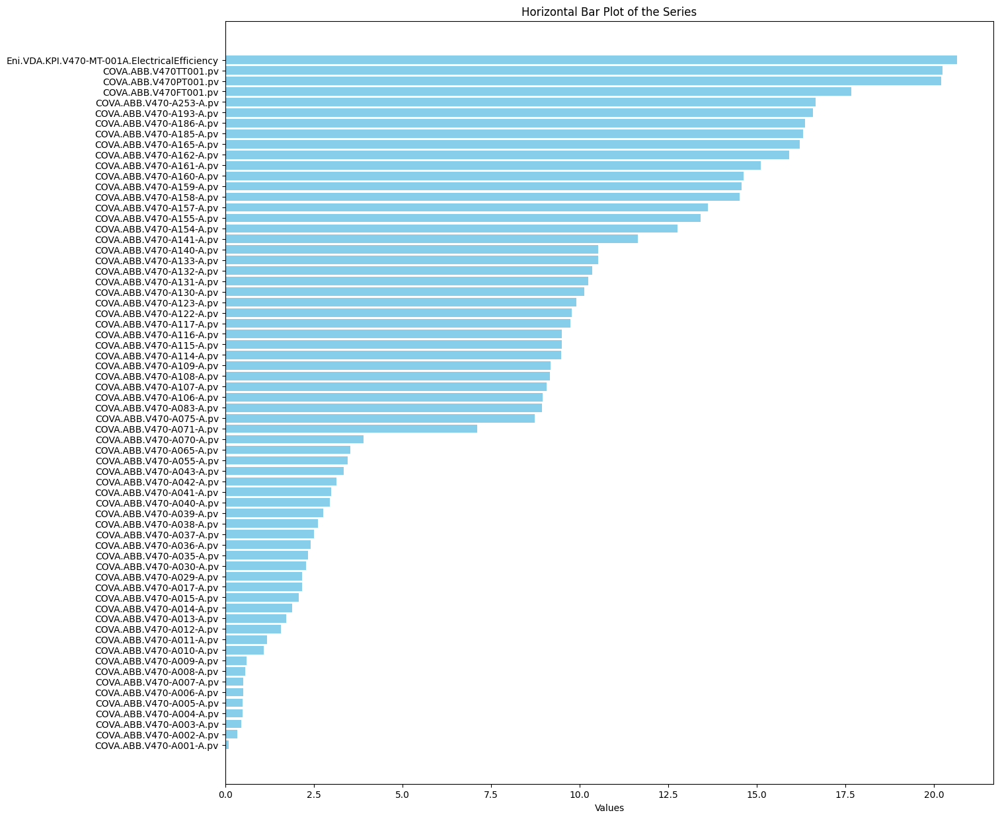

In [ ]:
plt.figure(figsize=(15, 15))
plt.barh(target_cols, vae_signal_test_col.sort_values(ascending = True), color='skyblue')
plt.xlabel('Values')
plt.title('Horizontal Bar Plot of the Series')
plt.show()

### Find the best threshold
Threshold optimization using different methos

In [ ]:
# Possible methods = ['bayesian' , 'simple' , 'cross_validation']
vae_best_threshold, vae_best_score = threshold_optimization(vae_signal_test_row, test_df['anomaly'], method = 'bayesian')

### Plot the reconstruction error with anomaly threshold

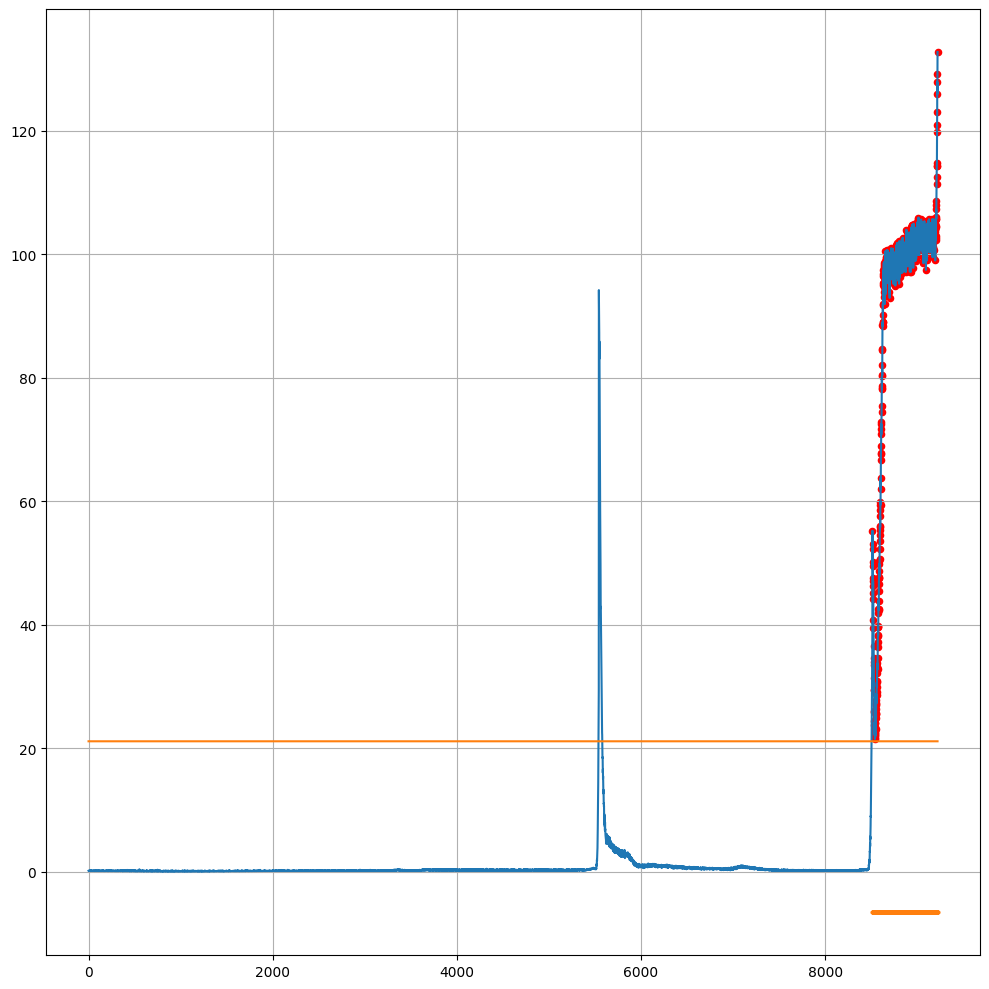

In [ ]:
plot_signal(vae_signal_test_row, labels =true_labels ,threshold = vae_best_threshold)

## VAE_LSTM

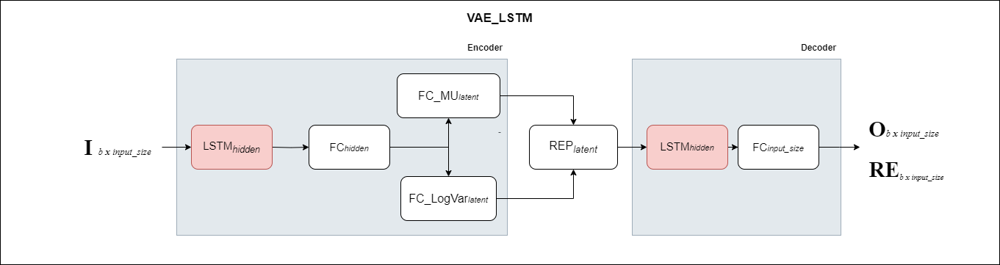

In [ ]:
vae_lstm = VAE_LSTM(input_size, hidden_size, latent_size, device = device).to(device)
_,_ = vae_lstm.fit(trdata_loader, num_epochs=epochs, plot_history = False)

Epoch 1/10, Loss: 0.0353
Epoch 2/10, Loss: 0.0290
Epoch 3/10, Loss: 0.0286
Epoch 4/10, Loss: 0.0283
Epoch 5/10, Loss: 0.0283
Epoch 6/10, Loss: 0.0284
Epoch 7/10, Loss: 0.0283
Epoch 8/10, Loss: 0.0283
Epoch 9/10, Loss: 0.0285
Epoch 10/10, Loss: 0.0286
Early stopping!


In [ ]:
vae_lstm_preds_test,vae_lstm_signal_test = vae_lstm.predict(tsdata_loader)

In [ ]:
# Convert into dataframe
vae_lstm_preds_test = pd.DataFrame(vae_lstm_preds_test.cpu().detach().numpy(), columns = target_cols)
vae_lstm_signal_test_col = pd.Series(vae_lstm_signal_test.mean(dim = 0).cpu().detach().numpy(), index = target_cols)
vae_lstm_signal_test_row = pd.Series(vae_lstm_signal_test.mean(dim = 1).cpu().detach().numpy())
vae_lstm_signal_test = pd.DataFrame(vae_lstm_signal_test.cpu().detach().numpy(), columns = target_cols)

### Signal comparison (ground truth vs prediction)




In [ ]:
plot_predicted_on_real_signal(test_df[target_cols], vae_lstm_preds_test)

### Plot the signal reconstruction error by feature

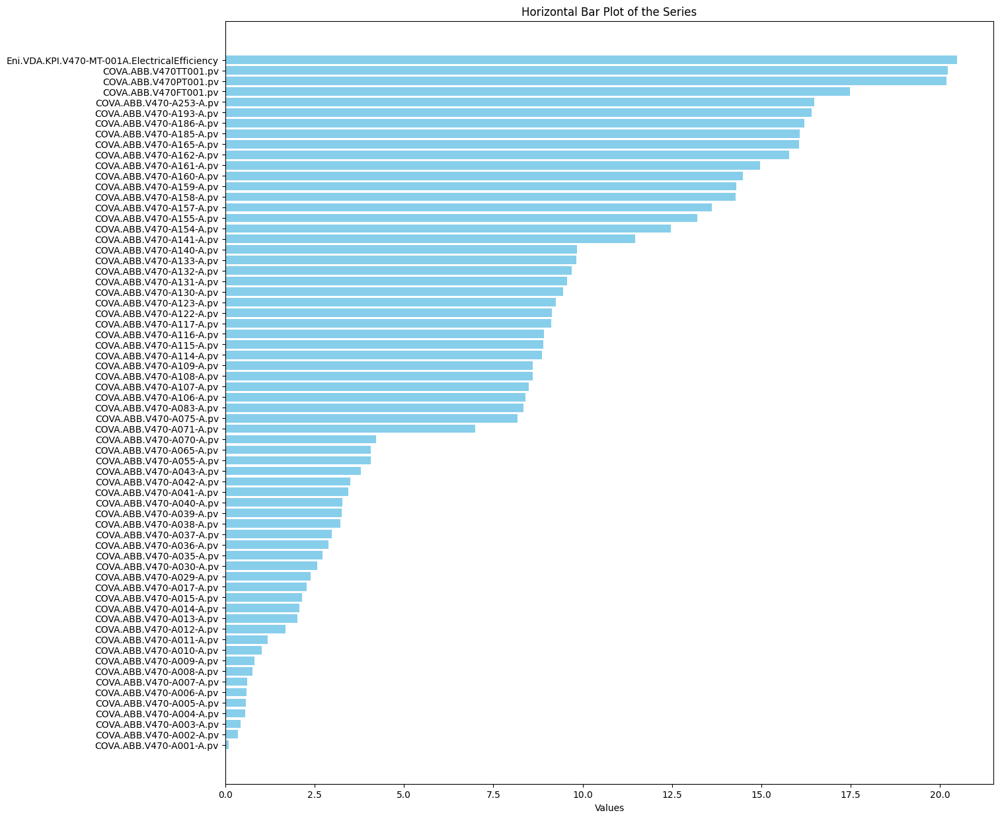

In [ ]:
plt.figure(figsize=(15, 15))
plt.barh(target_cols, vae_lstm_signal_test_col.sort_values(ascending = True), color='skyblue')
plt.xlabel('Values')
plt.title('Horizontal Bar Plot of the Series')
plt.show()

### Find the best threshold
Threshold optimization using different methos

In [ ]:
# Possible methods = ['bayesian' , 'simple' , 'cross_validation']
vae_lstm_best_threshold, vae_lstm_best_score = threshold_optimization(vae_lstm_signal_test_row, test_df['anomaly'], method = 'bayesian')

### Plot the reconstruction error with anomaly threshold

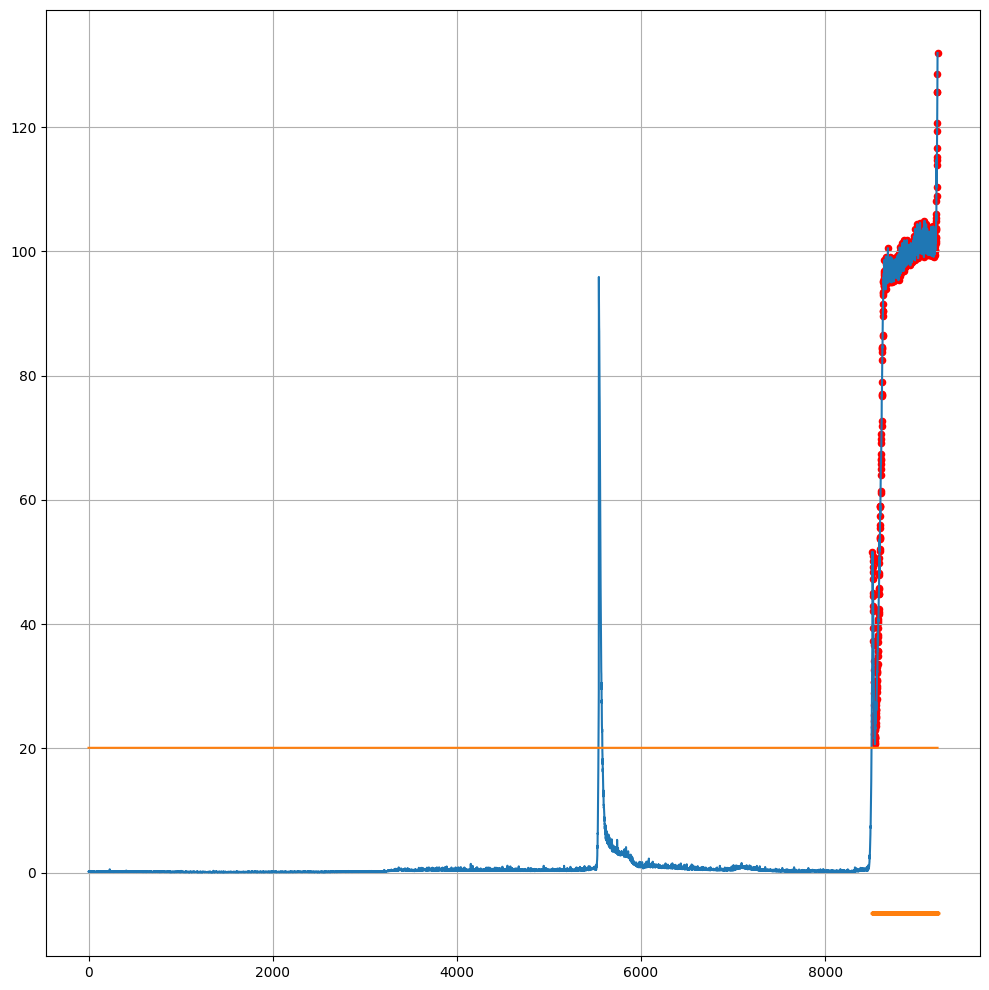

In [ ]:
plot_signal(vae_lstm_signal_test_row, labels =true_labels ,threshold = vae_lstm_best_threshold)

# FInal Comparison

AE vs AE_LSTM

In [ ]:
print(f'The mean of MSE for AE is: {np.mean(ae_signal_test)}')
print(f'The mean of MSE for AE_LSTM is: {np.mean(ae_lstm_signal_test)}')

The mean of MSE for AE is: 13.50370979309082
The mean of MSE for AE_LSTM is: 2.3692004680633545


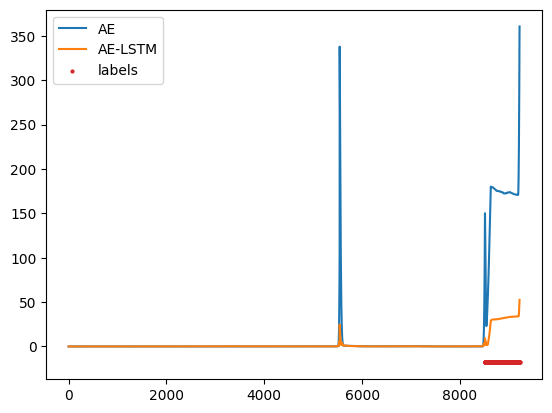

In [ ]:
labels = test_df['anomaly']

plt.plot(ae_signal_test_row, label = "AE")
plt.plot(ae_lstm_signal_test_row, label = "AE-LSTM")

s = 4
nonzero = ae_signal_test_row.index[labels != 0]
smin, smax = np.min(ae_signal_test_row), np.max(ae_signal_test_row)
lvl = smin - 0.05 * (smax - smin)
if plt is not None:
      plt.scatter(nonzero, np.ones(len(nonzero)) * lvl, s=s, color='tab:red', label='labels')
else:
      plt.scatter(nonzero, np.ones(len(nonzero)) * lvl, s=s, color='tab:red', label='labels')
plt.legend()
plt.show()

VAE vs VAE_LSTM

In [ ]:
print(f'The mean of the reconstruction error + KL divergence for VAE is {np.mean(vae_signal_test)}')
print(f'The mean of the reconstruction error + KL divergence for VAE_LSTM is {np.mean(vae_lstm_signal_test)}')

The mean of the reconstruction error + KL divergence for VAE is 7.942156791687012
The mean of the reconstruction error + KL divergence for VAE_LSTM is 7.696835041046143


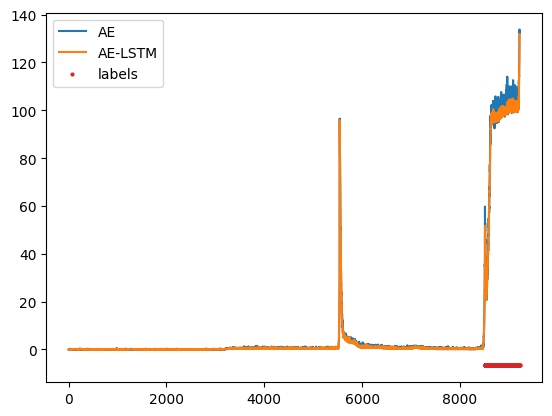

In [ ]:
labels = test_df['anomaly']

plt.plot(vae_signal_test_row, label = "AE")
plt.plot(vae_lstm_signal_test_row, label = "AE-LSTM")

s = 4
nonzero = vae_signal_test_row.index[labels != 0]
smin, smax = np.min(vae_signal_test_row), np.max(vae_signal_test_row)
lvl = smin - 0.05 * (smax - smin)
if plt is not None:
      plt.scatter(nonzero, np.ones(len(nonzero)) * lvl, s=s, color='tab:red', label='labels')
else:
      plt.scatter(nonzero, np.ones(len(nonzero)) * lvl, s=s, color='tab:red', label='labels')
plt.legend()
plt.show()

F1 in comparison

In [ ]:
score = pd.DataFrame(index = ['GMM', 'AE', 'AE_LSTM', 'VAE', 'VAE_LSTM'], columns = ['F1'])
score.loc['AE'] = ae_best_score
score.loc['AE_LSTM'] = ae_lstm_best_score
score.loc['VAE'] = vae_best_score
score.loc['VAE_LSTM'] = vae_lstm_best_score
score.loc['GMM'] = gmm_best_score

In [ ]:
score

,F1
GMM,0.988827
AE,0.949062
AE_LSTM,0.947368
VAE,0.965235
VAE_LSTM,0.966553


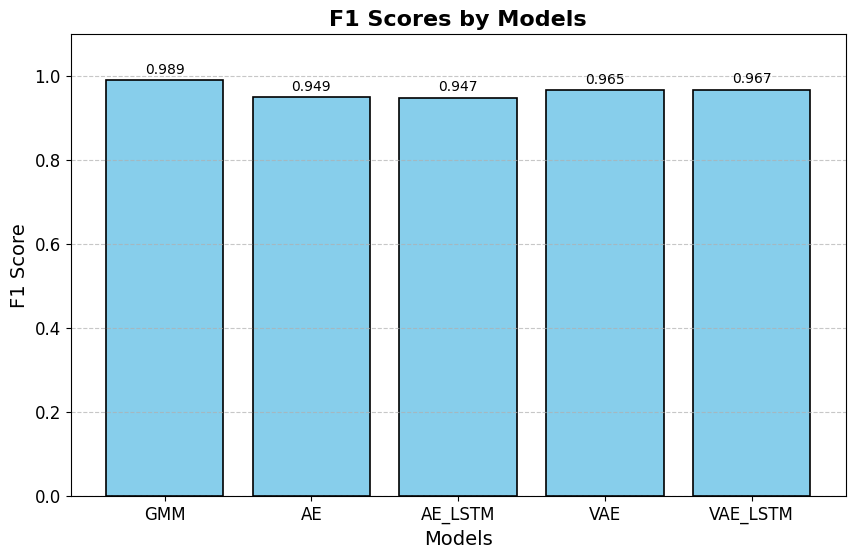

In [ ]:
# Plotting
plt.figure(figsize=(10, 6))
bars = plt.bar(score.index, score['F1'], color='skyblue', edgecolor='black', linewidth=1.2)

# Adding data labels on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.01, round(yval, 3), ha='center', va='bottom')

# Customizing the plot
plt.title('F1 Scores by Models', fontsize=16, fontweight='bold')
plt.xlabel('Models', fontsize=14)
plt.ylabel('F1 Score', fontsize=14)
plt.ylim(0, 1.1)  # Assuming F1 scores are between 0 and 1
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Display plot
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#Conclusion
All the 5 models performed very well on the test set. As we can see from the bar plot the baseline obtained the best results, but in our analysis this occurs because of a mislabeled anomaly in the test set. Indeed, we can see from the signal plots that in correspondece of the error-peaks of the 4 DL models there is a spike in the signal similar to anomalies.
The VAE_LSTM is the one that perform the best on this dataset, this could be related to the high degree of variability in data. The LSTM module handles better sequential dependencies and long-range temporal patterns.